# 03 · Conversion Experiment with a Two-Proportion Z-Test

**Portfolio recreation · aggregated synthetic counts**

**Question:** Is the conversion rate different between a baseline and a new software feature? The two-proportion z-test is appropriate for a binary outcome when the normal approximation is adequate.

In [1]:
from pathlib import Path
import sys
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from IPython.display import Image, display
from src.conversion_ab import two_proportion_z_test, evaluate
from src.visualize import save_conversion_chart


## 1 · View group metrics

In [2]:
r = evaluate()
print(f"Control:   {r['control_conversions']:,}/{r['control_users']:,} = {r['control_rate']:.2%}")
print(f"Treatment: {r['treatment_conversions']:,}/{r['treatment_users']:,} = {r['treatment_rate']:.2%}")
print(f"Absolute uplift: {r['absolute_lift']*100:.2f} percentage points")
print(f"Relative uplift: {r['relative_lift']:.2%}")

Control:   2,734/3,959 = 69.06%
Treatment: 2,906/4,041 = 71.91%
Absolute uplift: 2.86 percentage points
Relative uplift: 4.13%


## 2 · Z-test with pooled proportion

The z-score is computed as the difference in proportions (A − B) divided by the pooled standard error. A negative z-score **does not** imply universal superiority of B.

Pooled conversion rate: 0.7050
Z-statistic (A - B): -2.7996
Two-sided p-value: 0.005116
Reject H0 at alpha=0.05: True


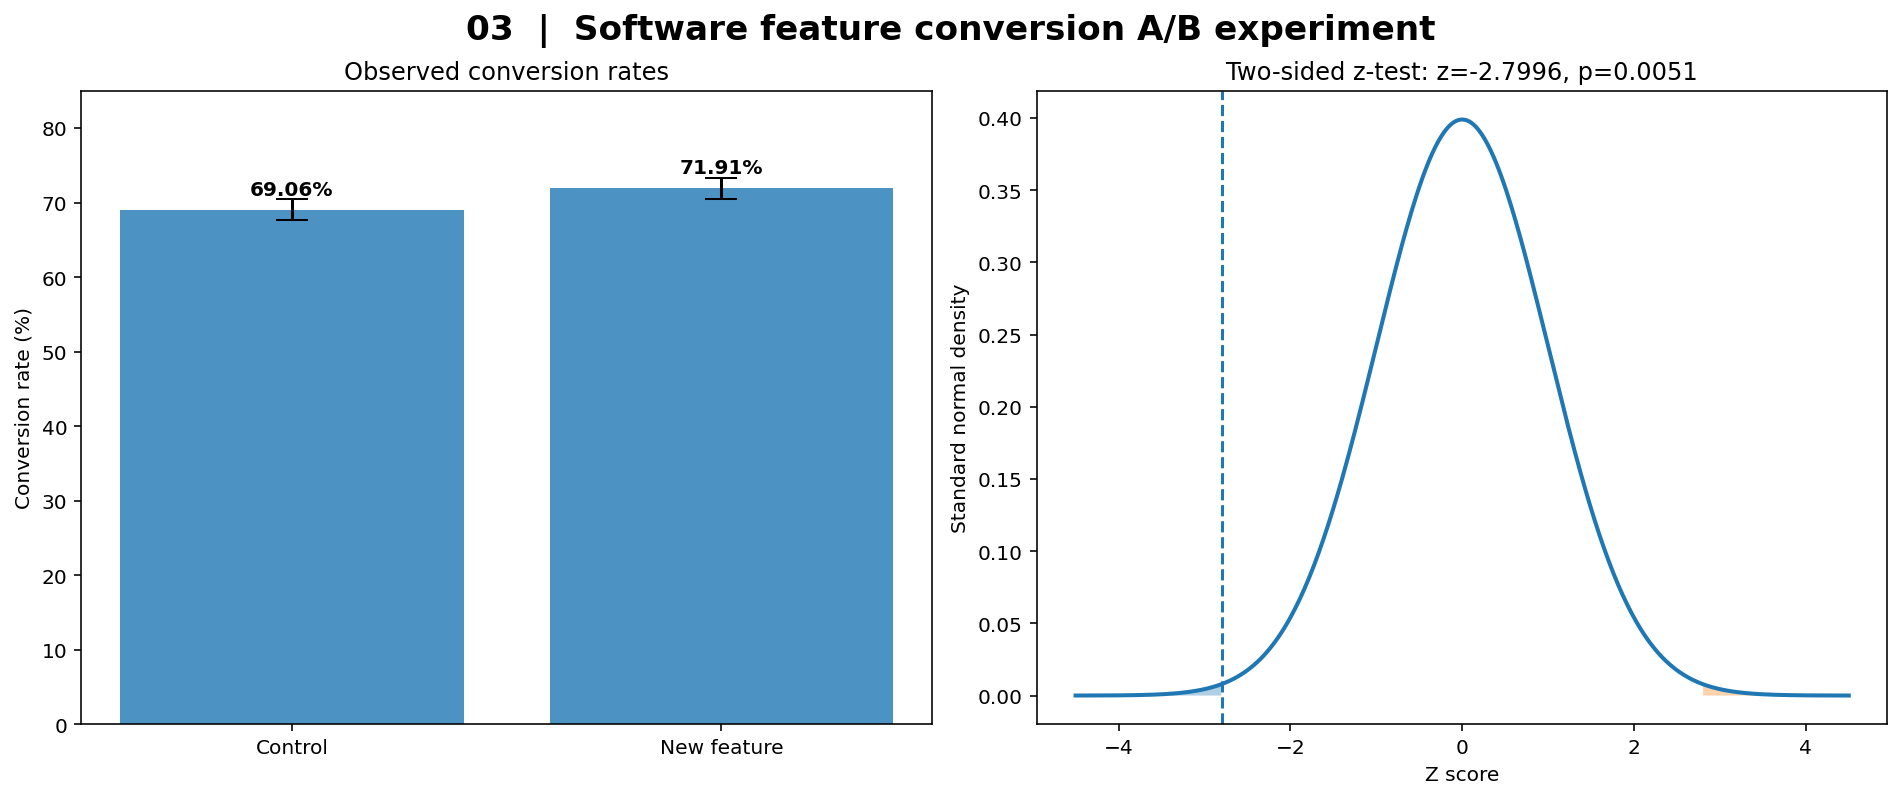

In [3]:
print(f"Pooled conversion rate: {r['pooled_rate']:.4f}")
print(f"Z-statistic (A - B): {r['z_statistic']:.4f}")
print(f"Two-sided p-value: {r['p_value']:.6f}")
print('Reject H0 at alpha=0.05:', r['reject_null'])
chart_path, _ = save_conversion_chart()
display(Image(filename=str(chart_path)))

## Takeaways and limitations

- The synthetic example indicates a statistically detectable difference at alpha=0.05.
- Significance alone cannot establish causal validity, business value, or universal product benefit.
- A production rollout would need randomisation checks, guardrail metrics, minimum sample planning, multiple-testing awareness, and consideration of confidence intervals and business impact.